# Task 4: Training Harness

## Resources

- [Sequence Classification](https://huggingface.co/docs/transformers/en/tasks/sequence_classification)
- [AutoModelForSequenceClassification](https://huggingface.co/docs/transformers/v5.20.2/en/model_doc/auto#transformers.AutoModelForSequenceClassification)
- [DataCollatorWithPadding](https://huggingface.co/docs/transformers/v5.20.2/en/main_classes/data_collator#transformers.DataCollatorWithPadding)
- [Subclassing Trainer methods](https://huggingface.co/docs/transformers/en/trainer_customize)
- [Datasets](https://huggingface.co/docs/datasets/en/use_dataset) and [Datasets with Pandas](https://huggingface.co/docs/datasets/en/use_with_pandas)

In [2]:
#@title Clone Repository (if using Google Colab)

import sys

IN_COLAB = 'google.colab' in sys.modules

if IN_COLAB:
    print("Running in Google Colab.")
    # 1. Step back to root first to prevent getcwd directory errors
    %cd -q /content

    # 2. Clear previous clones safely
    !rm -rf /content/Accenture-1O-contract-review-challenge

    # 3. Clone your Task 4 branch
    print("Cloning repo...")
    !git clone -q https://github.com/Break-Through-Tech/Accenture-1O-contract-review-challenge.git > /dev/null

    # 4. Move into the working directory
    %cd -q /content/Accenture-1O-contract-review-challenge/notebooks/

    print("\nCurrent Branch: ")

    !git branch --show-current
else:
    print("\nRunning in local environment.")

Running in Google Colab.
Cloning repo...

Current Branch: 
main


In [3]:
from pathlib import Path
import json

config_path = Path("october_task1_outputs/task1_frozen_model_specification.json")
with open(config_path, 'r', encoding='utf-8') as file:
    frozen_config = json.load(file)

MODEL_ID = frozen_config["encoder"]["primary_model_id"]
MODEL_NAME = frozen_config["encoder"]["primary_name"]
SEEDS = frozen_config["training"]["random_seeds"]
MAX_LENGTH = frozen_config["tokenization"]["max_length"]

FINAL_IDS = frozen_config["categories"]

OUTPUT_DIR = "october_task4_outputs"

print(f"Model: {frozen_config["encoder"]["primary_name"]}")
print(f"Seeds: {SEEDS}")

Model: Legal-BERT
Seeds: [42, 123, 2026]


In [4]:
#@title Check GPU

import torch
print("CUDA available:", torch.cuda.is_available(), "|", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "select a GPU runtime")

CUDA available: True | Tesla T4


# Load Data

Data is loaded from frozen chunks, already validated to have `max_length <= 512`, aligning with the frozen configration settings.

In [5]:
import pandas as pd
train_chunks = pd.read_parquet("task12b_outputs/train_chunks.parquet")
train_chunk_categories = pd.read_csv("task12b_outputs/train_chunk_categories.csv")

# note task12 named validation data with prefix "test"
val_chunks = pd.read_parquet("task12b_outputs/test_chunks.parquet")
val_chunk_categories = pd.read_csv("task12b_outputs/test_chunk_categories.csv")

train_chunks.columns.tolist()

['method',
 'contract_id',
 'context_group_id',
 'chunk_id',
 'chunk_number',
 'char_start',
 'char_end',
 'num_tokens',
 'chunk_text',
 'chunk_hash',
 'document_hash',
 'text']

## TEMPORARY

Build the `dataset` containing the chunk_id, text, gold labels, and mask. Later, this should be imported from Task 3.

In [6]:
def build_dataset(chunk_categories, chunks):
  df = chunk_categories.copy()
  df["is_contained"] = df["is_contained"].astype(str).str.lower().eq("true")

  Y = (df.pivot(index="chunk_id", columns="category_id", values="is_contained")
        [FINAL_IDS]            # columns parallel to FINAL_IDS order
        .astype(int))

  dataset = chunks[["chunk_id", "text"]].copy()
  dataset["labels"] = Y.loc[dataset["chunk_id"]].values.tolist()   # rows in chunk order
  dataset["mask"] = [[1] * len(FINAL_IDS)] * len(dataset)        # TODO: replace PLACEHOLDER mask

  return dataset

train_dataset = build_dataset(train_chunk_categories, train_chunks)
val_dataset = build_dataset(val_chunk_categories, val_chunks)

train_dataset.head()

,chunk_id,text,labels,mask
0,contract_0001__chunk_0000,EXHIBIT 10.6\n\n ...,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 1]","[1, 1, 1, 1, 1, 1, 1, 1, 1, 1]"
1,contract_0001__chunk_0001,1.1 Grant and Acceptance. Company h...,"[0, 0, 0, 0, 0, 0, 0, 0, 1, 1]","[1, 1, 1, 1, 1, 1, 1, 1, 1, 1]"
2,contract_0001__chunk_0002,such customers in the Market to those custom...,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0]","[1, 1, 1, 1, 1, 1, 1, 1, 1, 1]"
3,contract_0001__chunk_0003,1.2 License. The Company hereby grants ...,"[0, 0, 0, 0, 0, 0, 0, 0, 1, 0]","[1, 1, 1, 1, 1, 1, 1, 1, 1, 1]"
4,contract_0001__chunk_0004,sublicense the Names or to do ...,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0]","[1, 1, 1, 1, 1, 1, 1, 1, 1, 1]"


# Evaluation Metrics

We're using PR-AUC for our evaluation metric, as per the frozen configuration. We define `compute_metrics` for our model to later use.

In [7]:
import numpy as np
from scipy.special import expit
from sklearn.metrics import average_precision_score, f1_score

THRESHOLD = 0.5

def compute_metrics(eval_pred):
    logits = eval_pred.predictions
    labels, mask = eval_pred.label_ids

    # Same guarantees as the finite-score check: 10 finite scores per chunk
    assert logits.shape == labels.shape == mask.shape, (logits.shape, labels.shape, mask.shape)
    assert logits.shape[1] == len(FINAL_IDS)
    assert np.isfinite(logits).all(), "non-finite logits"

    probs = expit(logits)           # logistical sigmoid function
    labels = labels.astype(int)
    mask = mask.astype(bool)

    metrics, aps, f1s = {}, [], []
    for c, cat in enumerate(FINAL_IDS):
        keep = mask[:, c]                        # drop masked pairs for this category
        y, p = labels[keep, c], probs[keep, c]
        if len(np.unique(y)) < 2:                # PR-AUC is undefined with one class
            continue
        ap = average_precision_score(y, p)
        f1 = f1_score(y, p >= THRESHOLD, zero_division=0)
        metrics[f"pr_auc_{cat}"] = ap
        aps.append(ap)
        f1s.append(f1)

    metrics["n_categories_scored"] = len(aps)
    metrics["macro_pr_auc"] = float(np.mean(aps)) if aps else 0.0
    metrics["macro_f1_at_0.5"] = float(np.mean(f1s)) if f1s else 0.0

    return metrics

# Building the Model

| Parameter | Value | What it is |
|---|---|---|
| `model_name` | `"nlpaueb/legal-bert-base-uncased"` or your chosen encoder | First argument to `from_pretrained()` (officially `pretrained_model_name_or_path`). A Hub ID or local checkpoint path that loads the pretrained encoder weights and config. |
| `num_labels` | `10` (one per category) | Number of outputs in the classification head. A new, randomly initialized linear layer is added on top of the encoder. |
| `problem_type` | `"multi_label_classification"` | Selects the loss function. `"multi_label_classification"` uses `BCEWithLogitsLoss` (independent sigmoid per label). Alternatives are `"single_label_classification"` (softmax and cross-entropy) and `"regression"`. |
| `id2label` | `{0: "Cap On Liability", 1: ..., 9: ...}` | Dict mapping output index to category name. Makes predictions and saved checkpoints show names instead of `LABEL_0`, `LABEL_1`, etc. |
| `label2id` | `{"Cap On Liability": 0, ...}` | Inverse of `id2label`: category name to output index. Must be consistent with `id2label` and your label column order. |

**NOTE:** We can ignore the transformers warning: "You passed num_labels=10 which is incompatible to the id2label map of length 2."

> The code can’t be passing a length-2 id2label (len(FINAL_IDS) gives num_labels=10, so dict(enumerate(FINAL_IDS)) has 10 entries). The 2 almost certainly comes from the pretrained checkpoint’s base config, which defaults to two labels (LABEL_0, LABEL_1). from_pretrained loads that config first, then applies our kwargs on top. The check fires in the middle of that merge, when num_labels has been applied but our id2label hasn’t replaced the default yet.

In [8]:
from transformers import AutoTokenizer, AutoModelForSequenceClassification
from transformers.utils import logging as hf_logging

def load_model(model_name):
    """
    Args:
        model_name: Hugging Face model id, e.g. "distilbert/distilroberta-base"
    Returns:
        tokenizer, model
    """
    # Load the tokenizer
    tokenizer = AutoTokenizer.from_pretrained(model_name)

    old_level = hf_logging.get_verbosity()
    hf_logging.set_verbosity_error()          # hide warnings while loading

    # Load the model
    try:
        model = AutoModelForSequenceClassification.from_pretrained(
        model_name,
        num_labels=len(FINAL_IDS),                         # 10
        problem_type="multi_label_classification",         # uses BCEWithLogitsLoss
        id2label=dict(enumerate(FINAL_IDS)),               # records the approved order in the config
        label2id={c: i for i, c in enumerate(FINAL_IDS)},
        )
    finally:
        hf_logging.set_verbosity(old_level)   # restore, so later warnings still show

    return tokenizer, model

tokenizer, model = load_model(MODEL_ID)

assert model.config.num_labels == 10
assert model.config.id2label == dict(enumerate(FINAL_IDS))
assert model.config.problem_type == "multi_label_classification"
assert model.classifier.out_features == 10

print(type(model).__name__, "|", model.device, "|", model.dtype)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertForSequenceClassification | cpu | torch.float32


## Tokenize the datasets

Convert the DataFrames to HF datasets, tokenize text with truncation at the frozen max length, and keep input_ids, attention_mask, labels and mask.
Drop text and chunk_id from what the collator sees, but keep chunk_id somewhere so we can map scores back to chunks later.

- `labels` - classifies which of the 10 categories the input text contains
- `mask` - marks which of the 10 category pairs count toward the loss and metrics
- `input_ids` - the numerical representation of the text (each unique token maps to an id)
- `token_type_ids` - tells the model which sentence a token belongs to when you pass multiple sequences at once
- `attention_mask` - marks real tokens (1) versus padding (0) inside the text; used by the encoder

In [9]:
from datasets import Dataset

def preprocess(batch):
    return tokenizer(batch["text"], truncation=True, max_length=MAX_LENGTH)

def to_hf_dataset(df):
  dataset = Dataset.from_pandas(df, preserve_index=False)
  dataset = dataset.map(preprocess, batched=True)
  return dataset.remove_columns(["text", "chunk_id"])

train_chunk_ids = train_dataset["chunk_id"].tolist()
val_chunk_ids = val_dataset["chunk_id"].tolist()

train_ds = to_hf_dataset(train_dataset)
val_ds = to_hf_dataset(val_dataset)

train_ds.column_names

Map:   0%|          | 0/10841 [00:00<?, ? examples/s]

Map:   0%|          | 0/2873 [00:00<?, ? examples/s]

['labels', 'mask', 'input_ids', 'token_type_ids', 'attention_mask']

## Data Collator

Now create a batch of examples using DataCollatorWithPadding. The model takes a batch of shape (B, L): B chunks, each with L token IDs, but chunks may have different lengths. A batch must be rectangular, so we pad.

It’s more efficient to dynamically pad the sentences to the longest length in a batch during collation, instead of padding the whole dataset to the maximum length.

`DataCollatorWithPadding` pads input_ids and attention_mask, then converts everything in the batch to PyTorch tensors.

In [10]:
from transformers import DataCollatorWithPadding

data_collator = DataCollatorWithPadding(tokenizer=tokenizer) # function to be passed to a Trainer

## Trainer

The Trainer’s dataloader groups chunks into batches, and the collator pads them to the longest in the batch.
- A batch is a dict of tensors: input_ids (B, L), attention_mask (B, L), labels (B, 10), mask (B, 10).

By default, the Trainer computes BCE but it is not mask aware. `MaskedBCETrainer` multiplies the per-pair loss by mask and divides by the unmasked count. Masked pairs add nothing to the loss or the gradient.

- [BCEWithLogitsLoss](https://docs.pytorch.org/docs/2.14/generated/torch.nn.BCEWithLogitsLoss.html) - This loss combines a Sigmoid layer and the BCELoss in one single class. This version is more numerically stable than using a plain Sigmoid followed by a BCELoss as, by combining the operations into one layer, we take advantage of the log-sum-exp trick for numerical stability.

Excerpt from `frozen_config["training"]`:
```
"loss_function": "BCEWithLogitsLoss",
"imbalance_treatment": "Positive-class weighting",
"positive_weight_formula": "number of negative training examples / number of positive training examples",
"weight_data_source": "Training data only"
```

Suggestions:

The direction is:
1. Count training examples for each category. Count positive and negative chunk-category pairs where mask == 1. Exclude masked pairs, validation data, and test data. Compute these counts across the full model-training split, not separately per batch.
2. Calculate one weight per category:
   pos_weight = n_negative.float() / n_positive.float()
   For example, 900 negative and 100 positive pairs gives a weight of 9. That multiplies the positive-label loss contribution by nine, helping counter the imbalance. PyTorch documentation
3. Keep the weights in FINAL_IDS order. The result must be a float tensor of shape (10,), with each weight matching the corresponding label and model-output column. If a category has no usable positives or negatives, stop and investigate rather than silently substituting a weight.
4. Run the comparison:
   - pos_weight=None: the unweighted reference.
   - pos_weight=computed_weights: the imbalance-treatment candidate.
   Start both from the same initialization with comparable training settings. Compare validation precision, recall, and F1 per category to see whether weighting helps or creates too many false positives. This is the comparison required by the [October milestone (line 75)](/Users/elizabeth/work/btt-fall-2026/Accenture-1O-contract-review-challenge/docs/coach/october-execution/Accenture-Oct-Milestone.md:75).
One detail related to our earlier discussion: keep raw logits going into this loss. BCEWithLogitsLoss already includes sigmoid; the separate sigmoid step is for interpreting predictions afterward.

In [11]:
from transformers import Trainer
import torch

print("Loss Function: ", frozen_config["training"]["loss_function"])

class MaskedBCETrainer(Trainer):
  def __init__(self, *args, pos_weight=None, **kwargs):
    super().__init__(*args, **kwargs)
    # pos_weight: None = unweighted reference run.
    # Imbalance run: a (10,) float tensor in FINAL_IDS order = n_negative / n_positive per
    # category, counted over unmasked TRAINING pairs only (computed in the imbalance task).


    if pos_weight is not None:
      assert pos_weight.shape == (len(FINAL_IDS),), pos_weight.shape
    self.pos_weight = pos_weight

  def compute_loss(self, model, inputs, return_outputs=False, num_items_in_batch=None):
    """
    Args:
      model: the model
      inputs: a tensor containing the input_ids, attention_mask, labels, and mask
      return_outputs: whether or not to return outputs
      num_items_in_batch is passed by the Trainer but unused: we normalize by unmasked pairs instead
    Return:
      (loss, outputs) if return_outputs=True, otherwise just loss
    """
    labels = inputs["labels"].float()
    mask = inputs["mask"].float()

    # manually "pop" labels and masks in new dict
    model_inputs = {k: v for k, v in inputs.items() if k not in ("labels", "mask")}

    # feed new input back into model
    outputs = model(**model_inputs)     # loss=None, logits, hidden_state, attentions
    logits = outputs.logits.float()

    # calculate BCE loss
    pw = None if self.pos_weight is None else self.pos_weight.to(logits.device, torch.float32)
    loss_fn = torch.nn.BCEWithLogitsLoss(reduction="none", pos_weight=pw)
    losses = loss_fn(logits, labels)

    # apply the mask and average
    masked_sum = (losses * mask).sum()
    unmasked_pairs = mask.sum().clamp(min=1)
    total_loss = masked_sum / unmasked_pairs

    return (total_loss, outputs) if return_outputs else total_loss

Loss Function:  BCEWithLogitsLoss


In [12]:
#@title Test MaskedBCETrainer

from types import SimpleNamespace

logits = torch.randn(4, 10)
labels = torch.randint(0, 2, (4, 10)).float()

# 1) all-ones mask should equal plain BCE
mask = torch.ones(4, 10)
ours = (torch.nn.functional.binary_cross_entropy_with_logits(logits, labels, reduction="none") * mask).sum() / mask.sum().clamp(min=1)
ref = torch.nn.functional.binary_cross_entropy_with_logits(logits, labels)
# print(ours.item(), ref.item())          # should match
assert ours.item() == ref.item(), "should match"

# 2) flipping a masked pair's label must not change the loss
mask2 = mask.clone(); mask2[0, 0] = 0
def masked(l, y, m):
    return (torch.nn.functional.binary_cross_entropy_with_logits(l, y, reduction="none") * m).sum() / m.sum().clamp(min=1)
y2 = labels.clone(); y2[0, 0] = 1 - y2[0, 0]
# print(masked(logits, labels, mask2).item(), masked(logits, y2, mask2).item())   # should match
assert masked(logits, labels, mask2).item() == masked(logits, y2, mask2).item(), "should match"

# 3) test class
fake_model = lambda **kw: SimpleNamespace(logits=logits)   # returns our logits, ignores inputs
holder = SimpleNamespace(pos_weight=None)                  # stands in for `self`

def run(mask, labels=labels):
    inputs = {"input_ids": None, "labels": labels, "mask": mask}
    return MaskedBCETrainer.compute_loss(holder, fake_model, inputs).item()

assert abs(run(mask) - ref.item()) < 1e-6                        # 1) all-ones == plain BCE
assert abs(run(mask2) - run(mask2, y2)) < 1e-6                   # 2) masked flip changes nothing
assert run(torch.zeros(4, 10)) == 0.0                            # 3) fully masked batch -> 0, not NaN

print("All tests passed.")

All tests passed.


In [13]:
from transformers import TrainingArguments
import time

BATCH_SIZE = 16
NUM_CHUNKS = len(train_ds)
EPOCHS=3

def make_args(run_name, seed):
    """Provided: run name, seed -> fixed TrainingArguments. Use in train_once."""
    bf16 = torch.cuda.get_device_capability(0)[0] >= 8
    training_args = TrainingArguments(
      output_dir=f"{OUTPUT_DIR}/run_{run_name}",
      label_names=["labels", "mask"],
      seed=seed,

      # training budget
      learning_rate=2e-5,
      num_train_epochs=EPOCHS,
      per_device_train_batch_size=BATCH_SIZE,
      per_device_eval_batch_size=BATCH_SIZE,
      bf16=bf16,
      fp16=not bf16,

      # evaluate and save once per epoch, keep the best by validation macro PR-AUC
      eval_strategy="epoch",
      save_strategy="epoch",
      save_total_limit=2,
      load_best_model_at_end=True,
      metric_for_best_model="macro_pr_auc",

      # logging
      logging_steps=NUM_CHUNKS // BATCH_SIZE // 10,
      report_to="none",
    )
    return training_args

def train_once(model_to_train, run_name, seed, pos_weight=None):
    """
    Train one model on train_ds / val_ds and save its final model.
    Args:
        model_to_train: the model
    Returns:
        trainer, minutes: the Trainer object and the training time in minutes
    """
    args = make_args(run_name, seed)

    # initialize the Trainer
    trainer = MaskedBCETrainer(
      model=model_to_train,
      args=args,
      train_dataset=train_ds,
      eval_dataset=val_ds,
      processing_class=tokenizer,
      data_collator=data_collator,
      compute_metrics=compute_metrics,
      pos_weight=pos_weight
    )
    # run training, measure the minutes, save the model with save_pretrained
    start = time.time()
    trainer.train()
    end = time.time()
    minutes = (end - start) / 60.0

    model_to_train.save_pretrained(f"{OUTPUT_DIR}/final_{run_name}")

    return trainer, minutes

## Smoke Test

In [14]:
#@title Helper Functions

import matplotlib.pyplot as plt

def count_params(m): return sum(p.numel() for p in m.parameters() if p.requires_grad), sum(p.numel() for p in m.parameters())

def plot_loss(trainer, title):
    """Provided: plot train/validation loss from the completed Trainer logs."""
    logs = trainer.state.log_history
    tr = [(x["step"], x["loss"]) for x in logs if "loss" in x]; ev = [(x["step"], x["eval_loss"]) for x in logs if "eval_loss" in x]
    plt.figure(figsize=(5, 3)); plt.plot(*zip(*tr), label="train"); plt.plot(*zip(*ev), "o-", label="validation")
    plt.title(title); plt.xlabel("step"); plt.ylabel("loss"); plt.legend(); plt.show()
    print(f"loss {tr[0][1]:.3f} -> {tr[-1][1]:.3f}" + ("" if tr[-1][1] < tr[0][1] else "   WARNING: the loss did not decrease; check the labels"))

In [15]:
#@title 1. Smoke setup
import os, gc, json, shutil, traceback
import numpy as np
from transformers import set_seed

assert "real" not in globals(), "already in smoke mode: run Cell 4 (restore) first"

# pre-flight: every one of these should say 'function'
for name in ["count_params", "plot_loss", "load_model", "compute_metrics", "train_once", "make_args"]:
    print(f"{name:16s}", type(globals()[name]).__name__)

real = dict(train_ds=train_ds, val_ds=val_ds, NUM_CHUNKS=NUM_CHUNKS, EPOCHS=EPOCHS,
            SEEDS=SEEDS, OUTPUT_DIR=OUTPUT_DIR)

def with_synthetic_mask(ds, seed):
    rng = np.random.default_rng(seed)
    m = (rng.random((len(ds), len(FINAL_IDS))) > 0.15).astype(int)   # ~15% of pairs masked
    return ds.remove_columns("mask").add_column("mask", m.tolist())

train_ds = with_synthetic_mask(real["train_ds"].shuffle(seed=0).select(range(256)), 1)
val_ds   = with_synthetic_mask(real["val_ds"].shuffle(seed=0).select(range(128)), 2)
NUM_CHUNKS, EPOCHS = len(train_ds), 1
OUTPUT_DIR = f"{real['OUTPUT_DIR']}/smoke_tmp"      # keeps smoke files away from real ones
os.makedirs(OUTPUT_DIR, exist_ok=True)
print("smoke mode on:", len(train_ds), "train /", len(val_ds), "val chunks")

count_params     function
plot_loss        function
load_model       function
compute_metrics  function
train_once       function
make_args        function


Flattening the indices:   0%|          | 0/256 [00:00<?, ? examples/s]

Flattening the indices:   0%|          | 0/128 [00:00<?, ? examples/s]

smoke mode on: 256 train / 128 val chunks


In [16]:
print("real" in globals(), len(train_ds), EPOCHS, OUTPUT_DIR)

True 256 1 october_task4_outputs/smoke_tmp


In [17]:
#@title 2. Loop + checks
def run_loop(pw, seeds):
    condition = "unweighted" if pw is None else "weighted"
    results = {MODEL_NAME: {}}      # seed -> metrics/stats
    outputs = {MODEL_NAME: {}}      # seed -> saved logits

    for seed in seeds:
        run_name = f"{condition}_{MODEL_NAME}_seed{seed}"

        # Fresh model per seed; seed first so the new head init differs per seed
        set_seed(seed)
        _, model = load_model(MODEL_ID)
        trainer = None

        try:
            trainable, total = count_params(model)
            print(f"[seed {seed}] trainable {trainable:,} / {total:,} = {100 * trainable / total:.2f}%")
            assert trainable == total, "Full fine-tuning should train all parameters"

            torch.cuda.reset_peak_memory_stats()
            trainer, minutes = train_once(model, run_name, seed, pos_weight=pw)
            plot_loss(trainer, run_name)

            # trainer.model is the best-by-val-PR-AUC checkpoint (load_best_model_at_end)
            val_out = trainer.predict(val_ds)               # validation only; no test set

            # finite-value checks
            logits = val_out.predictions
            train_losses = [e["loss"] for e in trainer.state.log_history if "loss" in e]
            assert logits.shape == (len(val_ds), len(FINAL_IDS)), logits.shape
            assert np.isfinite(logits).all(), "non-finite validation logits"
            assert np.isfinite(train_losses).all(), "non-finite training loss"

            results[MODEL_NAME][seed] = {
                "status": "completed",
                "condition": condition,
                "pos_weight": None if pw is None else pw.tolist(),
                "trainable": trainable,
                "total": total,
                "minutes": round(minutes, 1),
                "peak VRAM GB": round(torch.cuda.max_memory_allocated() / 2**30, 2),
                "best val macro PR-AUC": trainer.state.best_metric,
                "checkpoint": trainer.state.best_model_checkpoint,
                "log_history": trainer.state.log_history,
            }
            outputs[MODEL_NAME][seed] = {
                "val_logits": val_out.predictions, "val_labels": val_out.label_ids,
            }
            print({k: v for k, v in results[MODEL_NAME][seed].items() if k != "log_history"})

        except Exception as e:
            traceback.print_exc()
            # keep failed runs in the record instead of crashing the loop
            results[MODEL_NAME][seed] = {
                "status": "failed", "condition": condition, "error": repr(e),
                "log_history": trainer.state.log_history if trainer is not None else [],
            }
            print(f"[seed {seed}] FAILED: {e!r}")

        finally:
            del trainer, model
            gc.collect()
            torch.cuda.empty_cache()

    with open(f"{OUTPUT_DIR}/results_{condition}.json", "w") as f:
        json.dump(results, f, indent=2, default=str)
    return results, outputs


def check_completed(results, outputs, seed, expect_weights=False):
    r = results[MODEL_NAME][seed]
    assert r["status"] == "completed", r.get("error")
    assert r["trainable"] == r["total"]
    assert os.path.isdir(r["checkpoint"]), "best checkpoint path missing"
    assert r["best val macro PR-AUC"] is not None

    train_losses = [e["loss"] for e in r["log_history"] if "loss" in e]
    evals = [e for e in r["log_history"] if "eval_macro_pr_auc" in e]
    assert len(train_losses) >= 2 and np.isfinite(train_losses).all(), train_losses
    assert len(evals) == EPOCHS, len(evals)

    o = outputs[MODEL_NAME][seed]
    assert o["val_logits"].shape == (len(val_ds), len(FINAL_IDS)) and np.isfinite(o["val_logits"]).all()
    labels, mask = o["val_labels"]
    assert labels.shape == mask.shape == o["val_logits"].shape
    assert mask.min() == 0, "synthetic mask did not reach the outputs"

    assert (r["pos_weight"] is not None) == expect_weights
    if expect_weights:
        assert len(r["pos_weight"]) == len(FINAL_IDS)

    print(f"seed {seed} OK | loss {train_losses[0]:.3f} -> {train_losses[-1]:.3f} "
          f"| categories scored {evals[-1]['eval_n_categories_scored']} "
          f"| {r['minutes']} min | peak {r['peak VRAM GB']} GB")

def check_file(condition, n_seeds):
    path = f"{OUTPUT_DIR}/results_{condition}.json"
    with open(path) as f:
        saved = json.load(f)
    assert len(saved[MODEL_NAME]) == n_seeds, saved[MODEL_NAME].keys()
    print("results json OK:", path)

def gpu_leak_check():
    gb = torch.cuda.memory_allocated() / 2**30
    print(f"GPU memory still allocated after cleanup: {gb:.2f} GB", "(OK)" if gb < 1 else "(something is holding the model)")

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[seed 42] trainable 109,489,930 / 109,489,930 = 100.00%


Epoch,Training Loss,Validation Loss,Pr Auc Governing Law,Pr Auc Revenue Profit Sharing,Pr Auc Cap On Liability,Pr Auc Anti Assignment,Pr Auc Audit Rights,Pr Auc License Grant,Pr Auc Exclusivity,N Categories Scored,Macro Pr Auc,Macro F1 At 0.5
1,0.490563,0.497794,0.190883,0.090909,0.019189,0.040963,0.066448,0.021972,0.016527,7,0.063841,0.000000


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

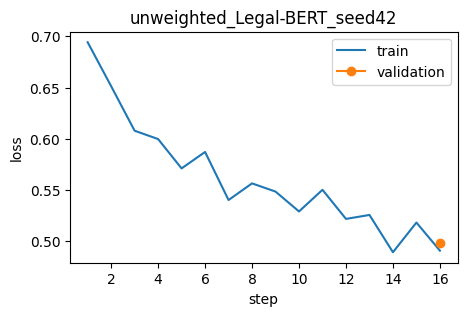

loss 0.694 -> 0.491


{'status': 'completed', 'condition': 'unweighted', 'pos_weight': None, 'trainable': 109489930, 'total': 109489930, 'minutes': 0.8, 'peak VRAM GB': 4.64, 'best val macro PR-AUC': 0.06384149641943813, 'checkpoint': 'october_task4_outputs/smoke_tmp/run_unweighted_Legal-BERT_seed42/checkpoint-16'}


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[seed 123] trainable 109,489,930 / 109,489,930 = 100.00%


Epoch,Training Loss,Validation Loss,Pr Auc Governing Law,Pr Auc Revenue Profit Sharing,Pr Auc Cap On Liability,Pr Auc Anti Assignment,Pr Auc Audit Rights,Pr Auc License Grant,Pr Auc Exclusivity,N Categories Scored,Macro Pr Auc,Macro F1 At 0.5
1,0.515438,0.505155,0.021139,0.014706,0.050505,0.212564,0.027817,0.028094,0.041667,7,0.056642,0.009852


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

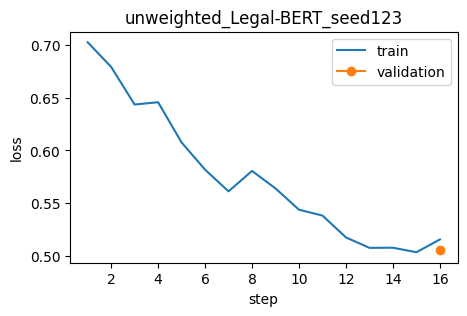

loss 0.703 -> 0.515


{'status': 'completed', 'condition': 'unweighted', 'pos_weight': None, 'trainable': 109489930, 'total': 109489930, 'minutes': 1.2, 'peak VRAM GB': 4.64, 'best val macro PR-AUC': 0.0566416723323493, 'checkpoint': 'october_task4_outputs/smoke_tmp/run_unweighted_Legal-BERT_seed123/checkpoint-16'}
seed 42 OK | loss 0.694 -> 0.491 | categories scored 7 | 0.8 min | peak 4.64 GB
seed 123 OK | loss 0.703 -> 0.515 | categories scored 7 | 1.2 min | peak 4.64 GB
results json OK: october_task4_outputs/smoke_tmp/results_unweighted.json
GPU memory still allocated after cleanup: 0.02 GB (OK)


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[seed 42] trainable 109,489,930 / 109,489,930 = 100.00%


Epoch,Training Loss,Validation Loss,Pr Auc Governing Law,Pr Auc Revenue Profit Sharing,Pr Auc Cap On Liability,Pr Auc Anti Assignment,Pr Auc Audit Rights,Pr Auc License Grant,Pr Auc Exclusivity,N Categories Scored,Macro Pr Auc,Macro F1 At 0.5
1,0.585063,0.618507,0.147143,0.023810,0.022381,0.031313,0.087376,0.021954,0.019091,7,0.050438,0.009998


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

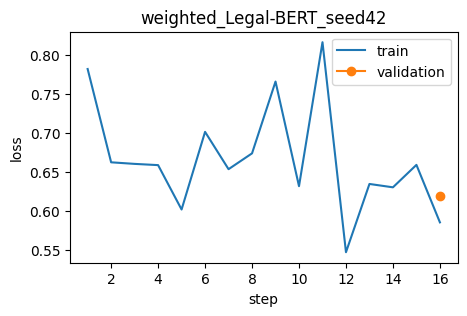

loss 0.782 -> 0.585


{'status': 'completed', 'condition': 'weighted', 'pos_weight': [1.0, 2.0, 3.0, 4.0, 5.0, 6.0, 7.0, 8.0, 9.0, 10.0], 'trainable': 109489930, 'total': 109489930, 'minutes': 0.8, 'peak VRAM GB': 4.64, 'best val macro PR-AUC': 0.050438050926477476, 'checkpoint': 'october_task4_outputs/smoke_tmp/run_weighted_Legal-BERT_seed42/checkpoint-16'}
seed 42 OK | loss 0.782 -> 0.585 | categories scored 7 | 0.8 min | peak 4.64 GB
results json OK: october_task4_outputs/smoke_tmp/results_weighted.json


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[seed 42] trainable 109,489,930 / 109,489,930 = 100.00%
[seed 42] FAILED: AssertionError(torch.Size([3]))


Traceback (most recent call last):
  File "/tmp/ipykernel_9467/1267431509.py", line 21, in run_loop
    trainer, minutes = train_once(model, run_name, seed, pos_weight=pw)
                       ~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/tmp/ipykernel_9467/178191342.py", line 48, in train_once
    trainer = MaskedBCETrainer(
      model=model_to_train,
    ...<6 lines>...
      pos_weight=pos_weight
    )
  File "/tmp/ipykernel_9467/3876025143.py", line 15, in __init__
    assert pos_weight.shape == (len(FINAL_IDS),), pos_weight.shape
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
AssertionError: torch.Size([3])


GPU memory still allocated after cleanup: 0.02 GB (OK)
failure path OK: AssertionError(torch.Size([3]))

ALL SMOKE CHECKS PASSED


In [18]:
#@title 3. Run smoke test (about 10 minutes)

# Scenario A: unweighted, two seeds (tests cleanup between seeds)
results, outputs = run_loop(pw=None, seeds=[42, 123])
for s in [42, 123]:
    check_completed(results, outputs, s)
check_file("unweighted", 2); gpu_leak_check()

# Scenario B: weighted (tests the pos_weight path)
results, outputs = run_loop(pw=torch.linspace(1, 10, len(FINAL_IDS)), seeds=[42])
check_completed(results, outputs, 42, expect_weights=True)
check_file("weighted", 1)

# Scenario C: bad weights on purpose. A traceback WILL print; that's expected.
results, outputs = run_loop(pw=torch.ones(3), seeds=[42])
r = results[MODEL_NAME][42]
assert r["status"] == "failed" and "torch.Size([3])" in r["error"], r["error"]
assert r["log_history"] == []
gpu_leak_check()
print("failure path OK:", r["error"][:80])

print("\nALL SMOKE CHECKS PASSED")

In [19]:
#@title 4. Restore real settings
train_ds, val_ds = real["train_ds"], real["val_ds"]
NUM_CHUNKS, EPOCHS, SEEDS = real["NUM_CHUNKS"], real["EPOCHS"], real["SEEDS"]
assert "smoke_tmp" in OUTPUT_DIR
shutil.rmtree(OUTPUT_DIR)                 # smoke checkpoints are ~1.3 GB each
OUTPUT_DIR = real["OUTPUT_DIR"]
del real
print("restored:", len(train_ds), "train chunks,", EPOCHS, "epochs, seeds", SEEDS)

restored: 10841 train chunks, 3 epochs, seeds [42, 123, 2026]


# Run Loop

In [20]:
# unweighted reference
results_unw, outputs_unw = run_loop(pw=None, seeds=SEEDS)

# later, once the weights exist: a (10,) float tensor in FINAL_IDS order
# results_w, outputs_w = run_loop(pw=computed_weights, seeds=SEEDS)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[seed 42] trainable 109,489,930 / 109,489,930 = 100.00%


Epoch,Training Loss,Validation Loss


KeyboardInterrupt: 